In [39]:
import sys 
sys.path.append("..")
# ou sys.path.append("/home/onyxia/work")
import libsigma

In [40]:
import os
from sklearn.model_selection import train_test_split

# personal librairies
from libsigma import classification as cla

# 1 --- define parameters
# inputs
my_folder = '/home/onyxia/work/data/td_classif'
sample_filename = os.path.join(my_folder, 'sample_strata.tif')
image_filename = os.path.join(my_folder, 'aumelas_orthoirc.tif')

# 2 --- extract samples
X, Y, t = cla.get_samples_from_roi(image_filename, sample_filename)

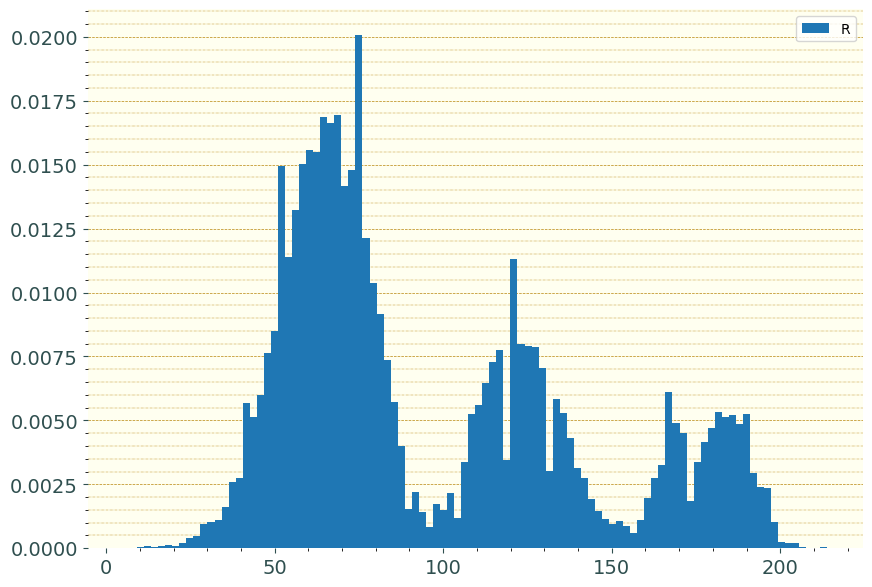

In [3]:
import matplotlib.pyplot as plt
from libsigma import plots

# create plot
fig, ax = plt.subplots(figsize=(10, 7))

# here we decide to plot the Red band
labels = ['R']
band = X[:, 1]
vals, bins, patch = ax.hist(band,  # band to display
                            bins=100, # number of binds
                            label=labels, # for the legend
                            density=True, # if counts are normalized
                            zorder=2)

# display the legend
ax.legend()

# custom the background
ax = plots.custom_bg(ax, x_grid=False)

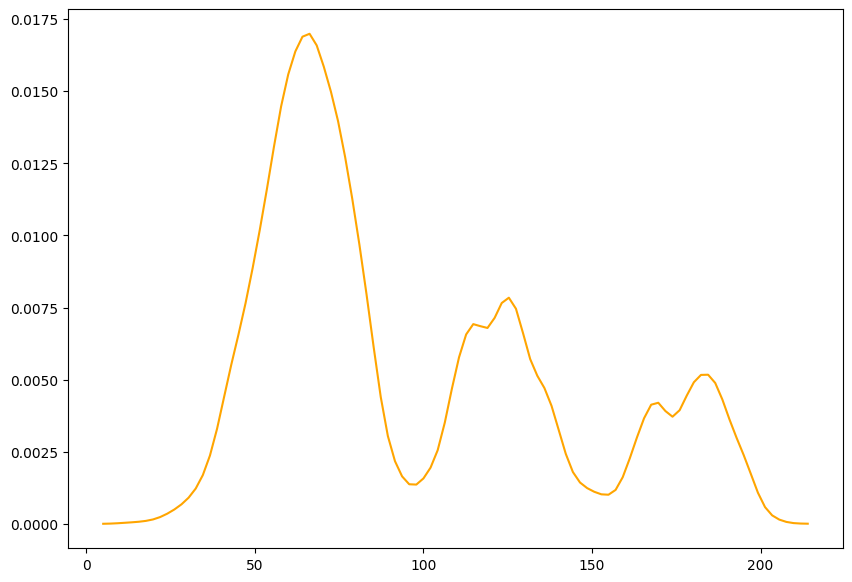

In [4]:
import numpy as np
from sklearn.neighbors import KernelDensity

# get band to display
band = X[:, 1]

# get 100 values between the min and the max of band
X_plot = np.linspace(band.min(), band.max(), 100)[:, np.newaxis]

# define kernel density
kde = KernelDensity(bandwidth=3)
# learn kernel
kde.fit(band.reshape(-1, 1))
# predict on our X
log_dens = kde.score_samples(X_plot)
density = np.exp(log_dens)

# plot it
fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(X_plot[:,0], density , color='orange',
        zorder=3, linewidth=1.5,
        linestyle='-')

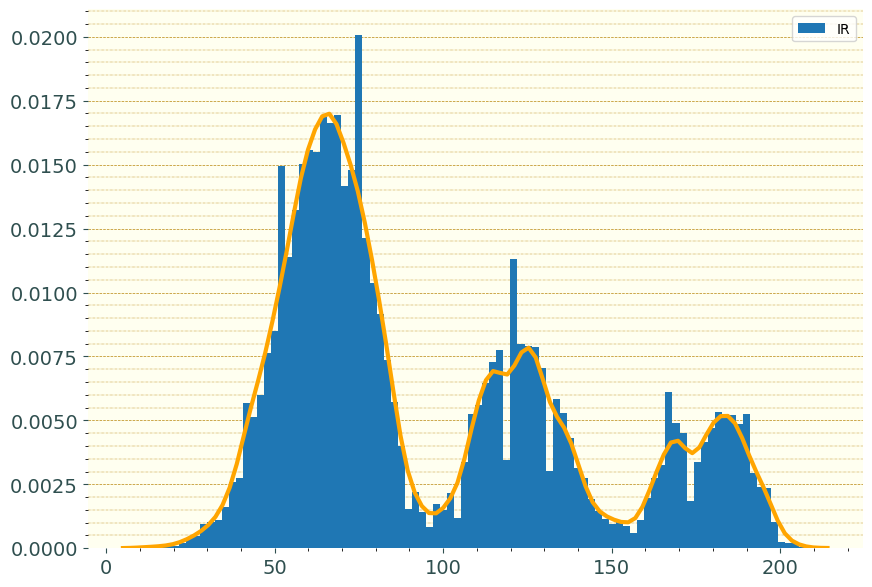

In [5]:
fig, ax = plt.subplots(figsize=(10, 7))
num_band = 1
labels = ['IR', 'R', 'G']

band = X[:, num_band]
label = labels[num_band]
vals, bins, patch = ax.hist(band, bins=100, label=labels, density=True,
                           zorder=2)
ax.legend()
ax = plots.custom_bg(ax, x_grid=False)

# get 100 values between the min and the max of band
X_plot = np.linspace(band.min(), band.max(), 100)[:, np.newaxis]

# define kernel density
kde = KernelDensity(bandwidth=3)
# learn kernel
kde.fit(band.reshape(-1, 1))
# predict on our X
log_dens = kde.score_samples(X_plot)
density = np.exp(log_dens)

# plot it
ax.plot(X_plot[:,0], density , color='orange',
        zorder=3, linewidth=3,
        linestyle='-')

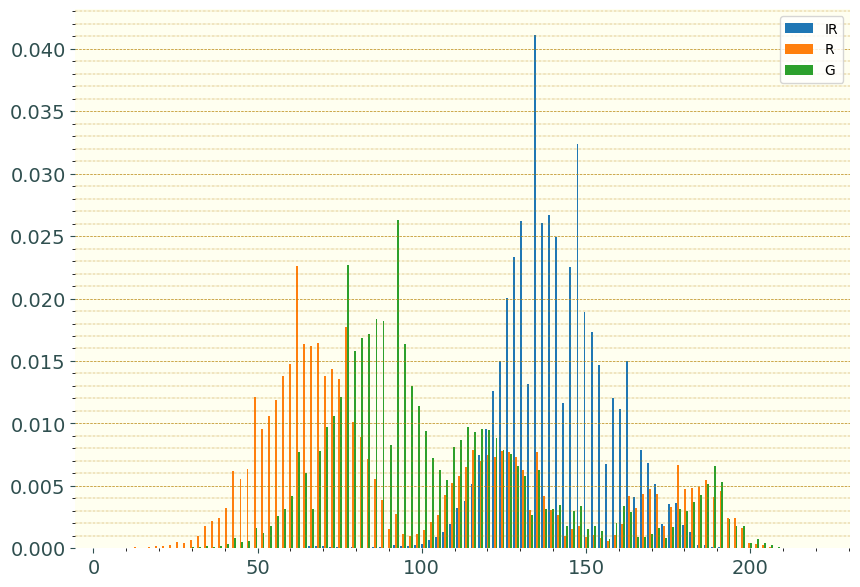

In [6]:
fig, ax = plt.subplots(figsize=(10, 7))
labels = ['IR', 'R', 'G']
vals, bins, patch = ax.hist(X, bins=100, label=labels, density=True)
ax.legend()
ax = plots.custom_bg(ax, x_grid=False)

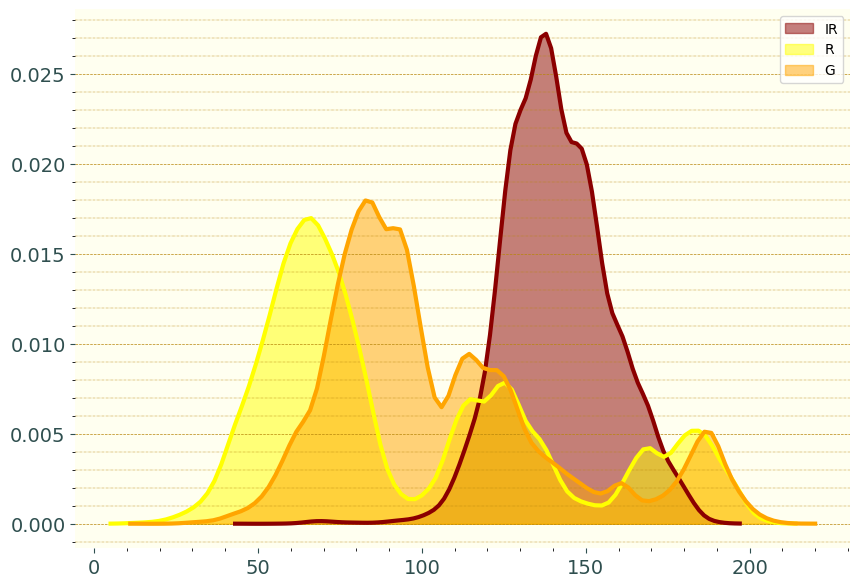

In [7]:
import numpy as np
from sklearn.neighbors import KernelDensity
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 7))

color = ['darkred', 'yellow', 'orange']
labels = ['IR', 'R', 'G']
for idx_band, col, label in zip(range(3), color, labels):
    band = X[:, idx_band]    
    # get 100 values between the min and the max of band
    X_plot = np.linspace(band.min(), band.max(), 100)[:, np.newaxis]

    # define kernel density
    kde = KernelDensity(bandwidth=3)
    # learn kernel
    kde.fit(band.reshape(-1, 1))
    # predict on our X
    log_dens = kde.score_samples(X_plot)
    density = np.exp(log_dens)

    # plot it
    ax.plot(X_plot[:,0], density , color=col,
            zorder=3, linewidth=3,
            linestyle='-')
    # fill space between lines and the x axis (0)
    ax.fill_between(X_plot[:,0], 0, density, alpha=0.5, color=col, label=label)

ax.legend()
ax = plots.custom_bg(ax, x_grid=False)

<class 'matplotlib.figure.Figure'>
<class 'matplotlib.axes._axes.Axes'>


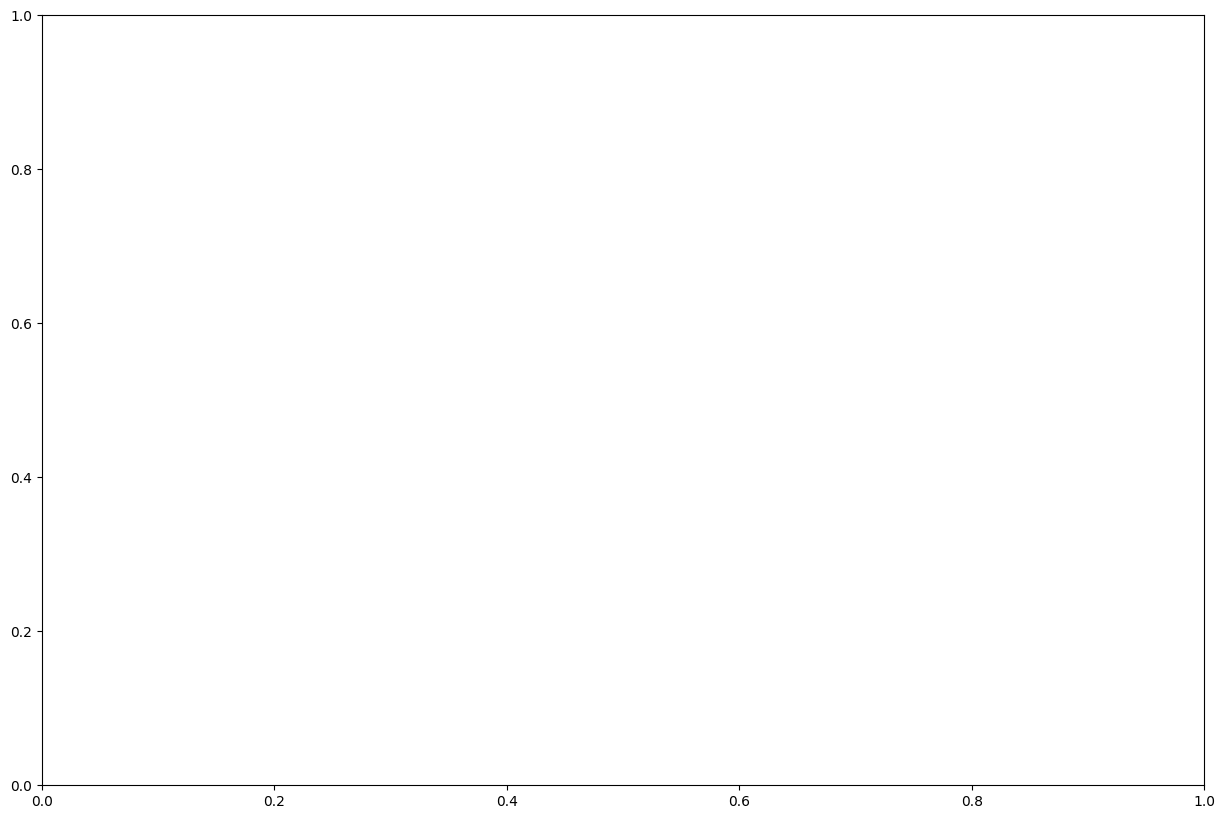

In [8]:
fig, ax = plt.subplots(figsize=(15, 10))
print(type(fig))
print(type(ax))

<class 'numpy.ndarray'>
(2, 2)
<class 'matplotlib.axes._axes.Axes'>


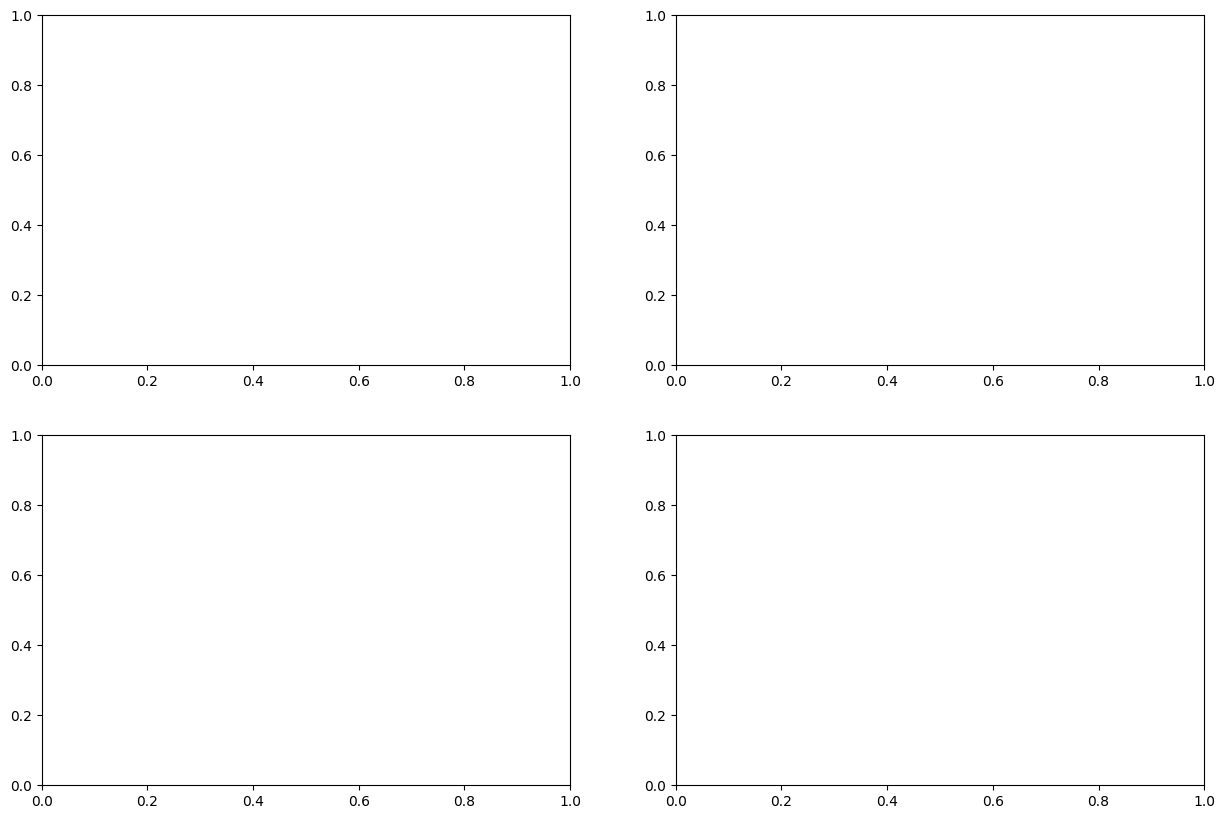

In [9]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))
print(type(axes))
print(axes.shape)
print(type(axes[0,0]))

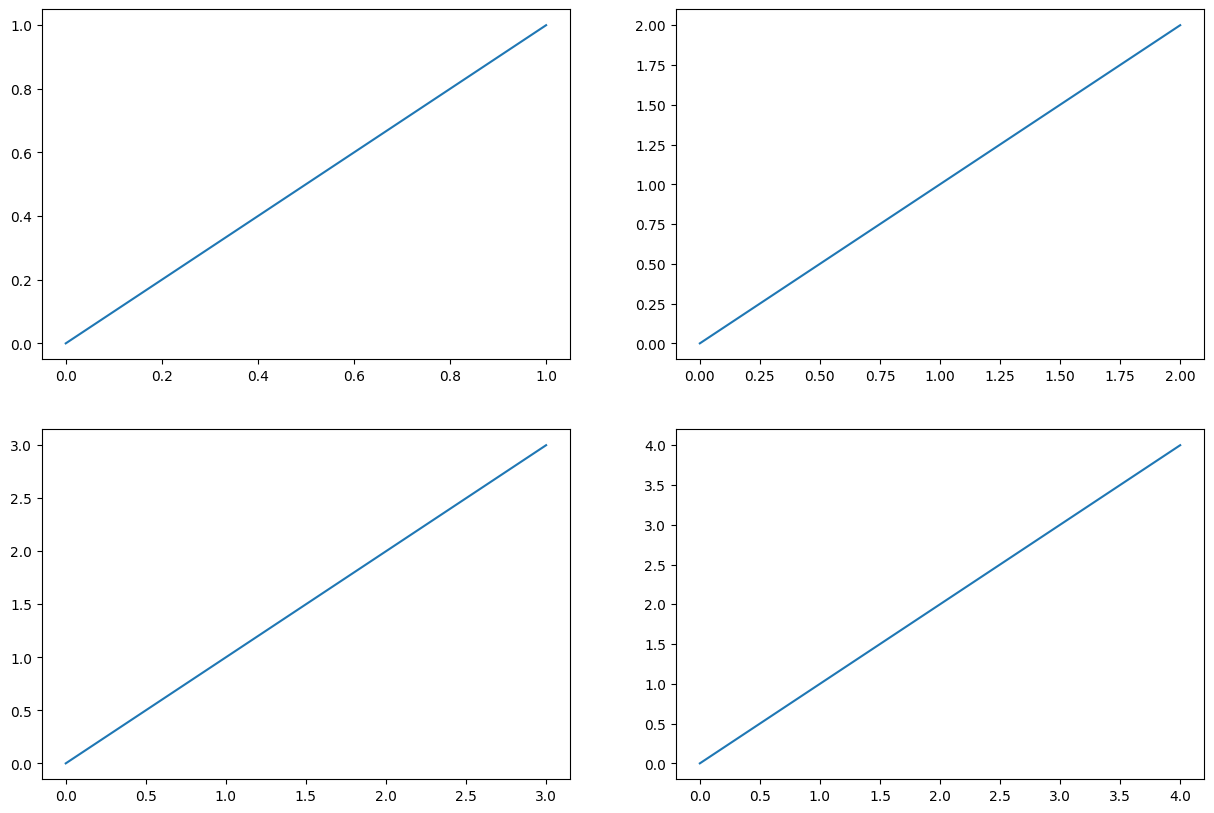

In [10]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))
for i, ax in enumerate(axes.flatten()):
    data = range(0, i + 2)
    ax.plot(data, data)

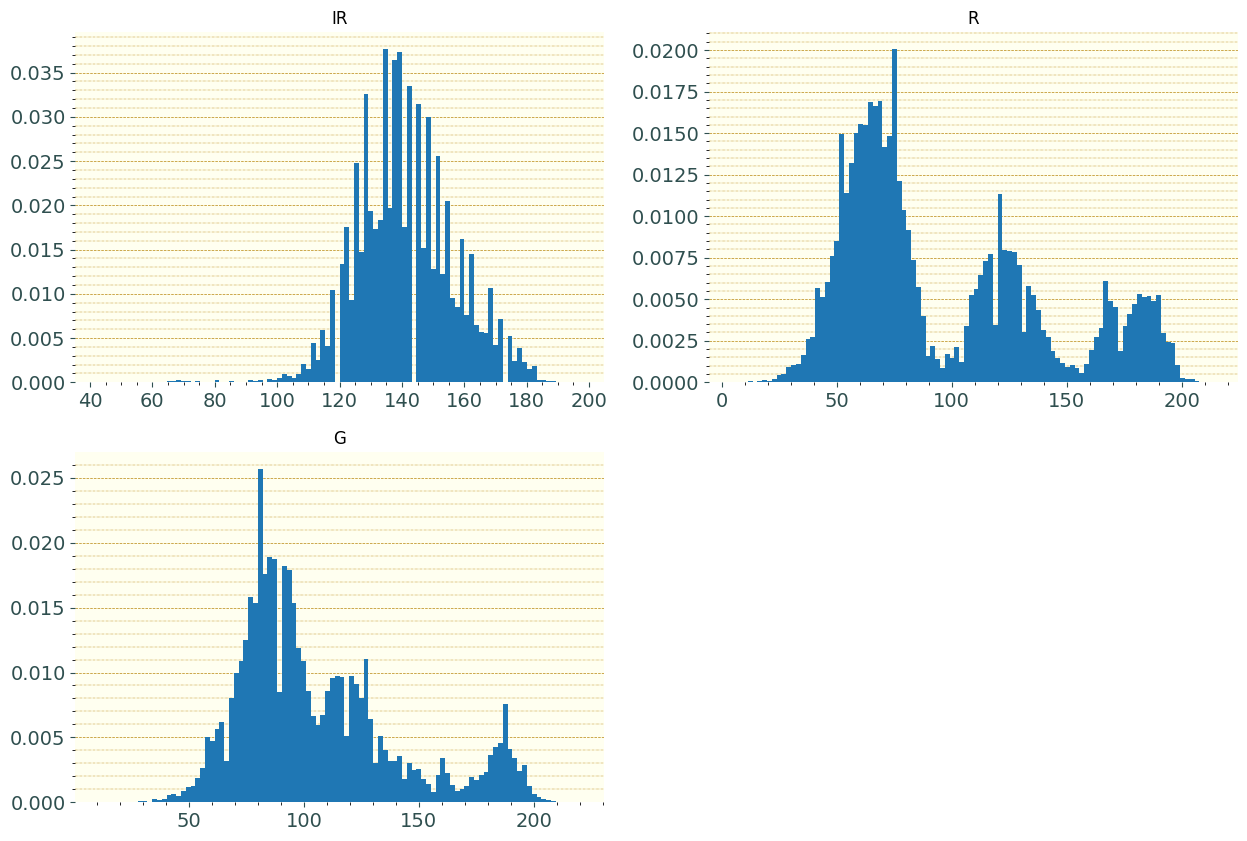

In [11]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))
list_title = ['IR', 'R', 'G']
my_iterator = zip(axes.flatten(), list_title)
for i, (ax, title) in enumerate(my_iterator):
    band = X[:, i]
    vals, bins, patch = ax.hist(band, bins=100,  density=True, zorder=2)
    ax.set_title(title)
    ax = plots.custom_bg(ax, x_grid=False)

_ = axes[1][1].axis('off')

(np.float64(0.0), np.float64(1.0), np.float64(0.0), np.float64(1.0))

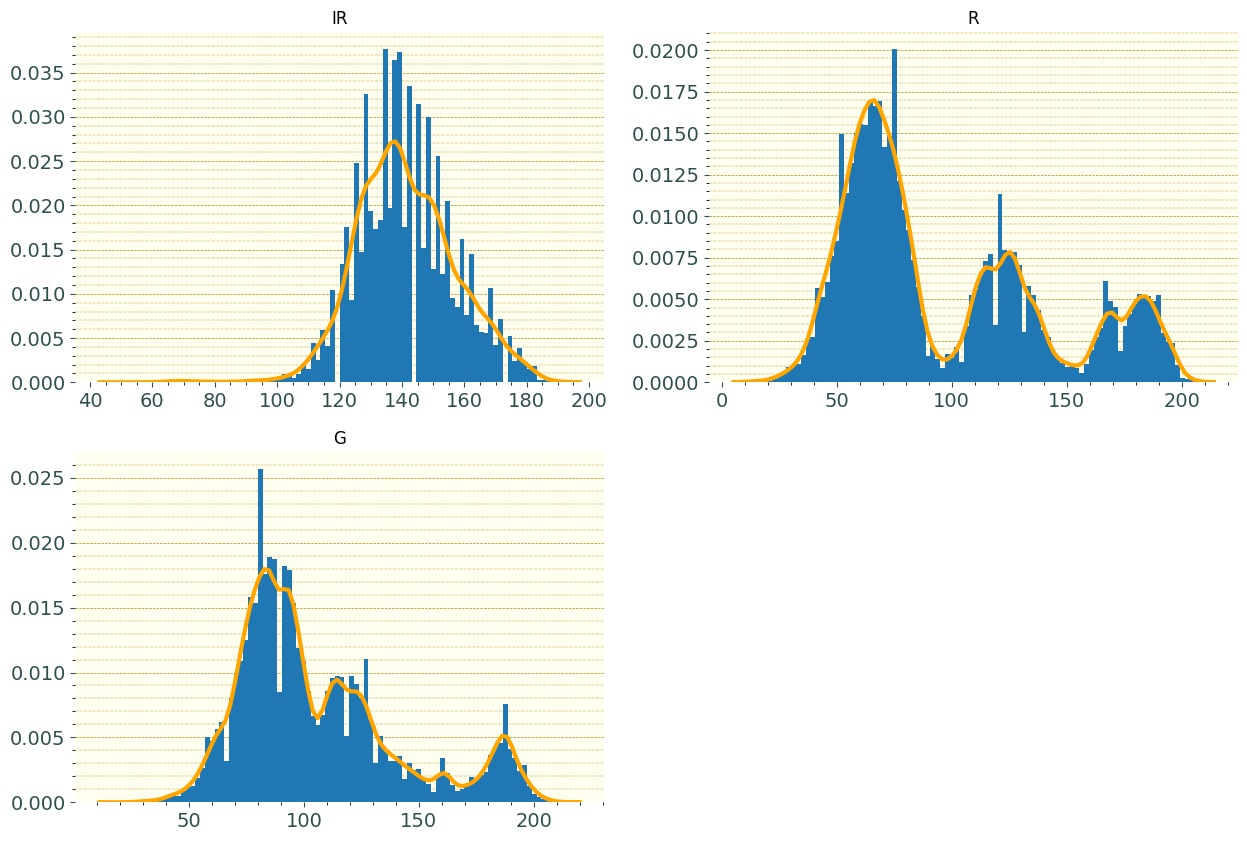

In [12]:
import numpy as np
from sklearn.neighbors import KernelDensity

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))
list_title = ['IR', 'R', 'G']
my_iterator = zip(axes.flatten(), list_title)
for i, (ax, title) in enumerate(my_iterator):    
    band = X[:, i]
    vals, bins, patch = ax.hist(band, bins=100, label=labels, density=True,
                           zorder=2)

    # get 100 values between the min and the max of band
    X_plot = np.linspace(band.min(), band.max(), 100)[:, np.newaxis]

    # define kernel density
    kde = KernelDensity(bandwidth=3)
    # learn kernel
    kde.fit(band.reshape(-1, 1))
    # predict on our X
    log_dens = kde.score_samples(X_plot)
    density = np.exp(log_dens)

    # plot it
    ax.plot(X_plot[:,0], density ,zorder=3, linewidth=3,
            linestyle='-', color='orange')
    ax.set_title(title)
    ax = plots.custom_bg(ax, x_grid=False)
axes[1][1].axis('off')

In [13]:
dict_X, ditc_Y, dict_t = cla.get_samples_from_roi(image_filename, sample_filename, output_fmt='by_label')


In [14]:
print(dict_X.keys())


dict_keys([np.int32(1), np.int32(2), np.int32(3), np.int32(4)])


In [15]:
print(dict_X[1])


[[175 193 195]
 [178 194 196]
 [174 193 192]
 ...
 [162 181 180]
 [168 187 187]
 [167 189 189]]


In [16]:
condition = (Y==1)
condition.shape
condition = condition[:,0]
X_1 = X[condition]
print(X_1.shape)

(4177, 3)


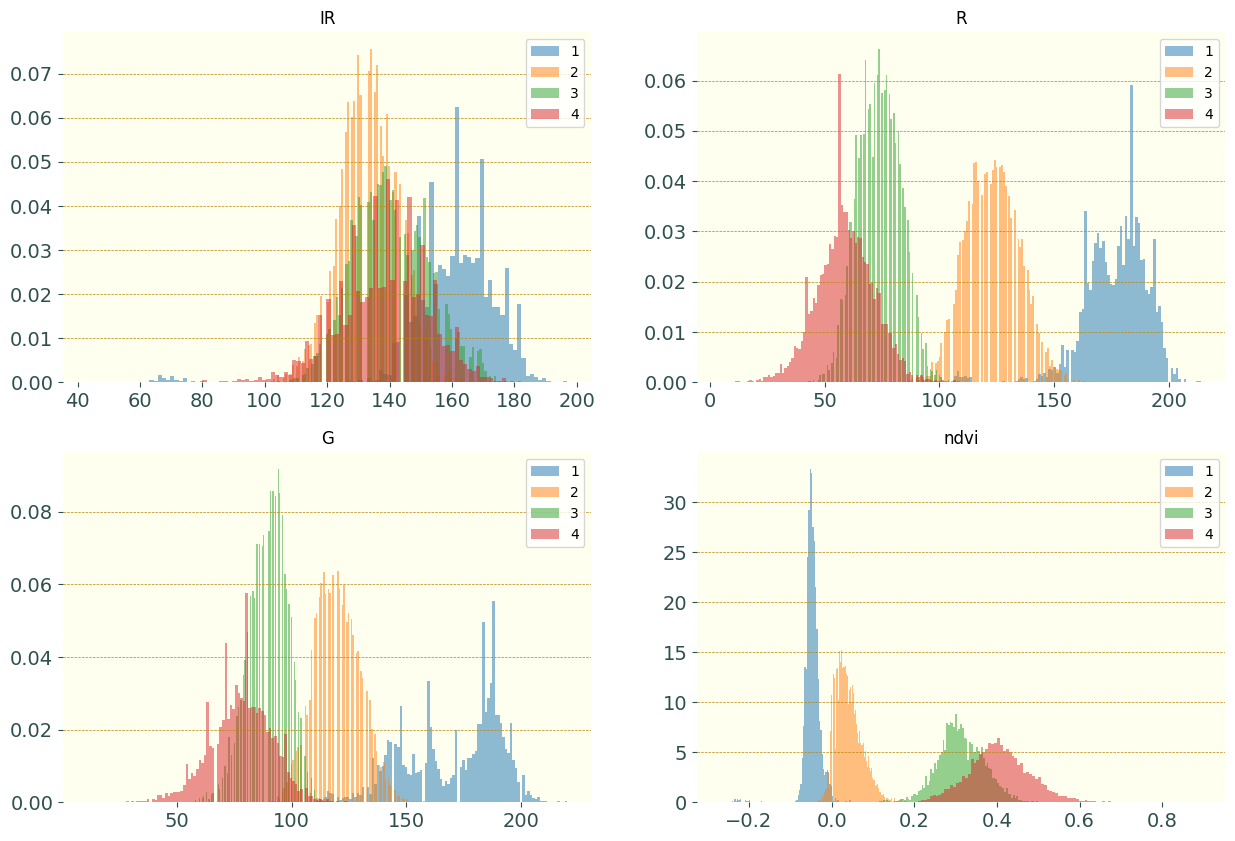

In [17]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))
list_title = ['IR', 'R', 'G', 'ndvi']
my_iterator = zip(axes.flatten(), list_title)
for i, (ax, title) in enumerate(my_iterator):    
    for class_number, X in dict_X.items():
        if i ==3 :
            X = X.astype('int16') # Warning, you'll have unexpected results
                                  # if you keep data type as 'uint8'
                                  # try it if you're curious
            ir = X[:, 0]
            r =  X[:, 1]
            band = (ir -r) / (ir + r)
        else:
            band = X[:, i]
        vals, bins, patch = ax.hist(band, bins=100,  density=True, label=class_number, alpha=0.5)
    ax.set_title(title)
    ax = plots.custom_bg(ax, x_grid=False, minor=False)
    ax.legend()


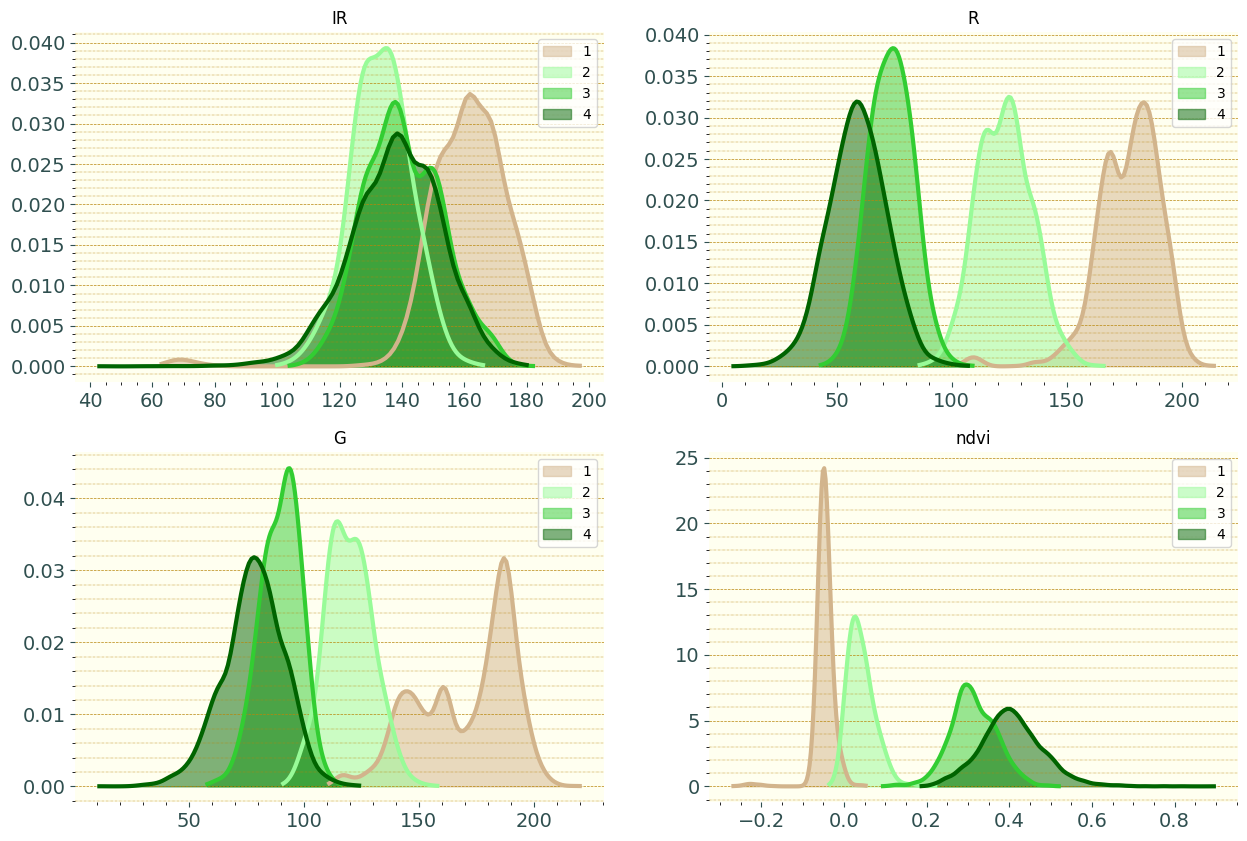

In [18]:
from sklearn.neighbors import KernelDensity
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))
list_title = ['IR', 'R', 'G', 'ndvi']
my_iterator = zip(axes.flatten(), list_title)
color = ['tan', 'palegreen', 'limegreen', 'darkgreen']
for i, (ax, title) in enumerate(my_iterator):    
    for (class_number, X), col in zip(dict_X.items(), color):
        if i ==3 :
            X = X.astype('int16')
            band = (X[:, 0] - X[:, 1]) / (X[:, 0] + X[:, 1])
            bandwidth = 0.01
        else:
            band = X[:, i]
            bandwidth = 3

        # get 100 values between the min and the max of band
        X_plot = np.linspace(band.min(), band.max(), 100)[:, np.newaxis]

        # define kernel density
        kde = KernelDensity(bandwidth=bandwidth)
        # learn kernel
        kde.fit(band.reshape(-1, 1))
        # predict on our X
        log_dens = kde.score_samples(X_plot)
        density = np.exp(log_dens)

        # plot it
        ax.plot(X_plot[:,0], density ,zorder=3, linewidth=3,
                linestyle='-', color=col)
        # fill with color the space between the curve and the line x=0
        ax.fill_between(X_plot[:,0], 0, density, alpha=0.5, color=col, label=class_number)
        ax.set_title(title)
        ax = plots.custom_bg(ax, x_grid=False)
    ax.set_title(title)
    ax = plots.custom_bg(ax, x_grid=False, minor=False)
    ax.legend()


In [19]:
import pandas as pd
# concatenate X and Y
data = np.concatenate((X, Y), axis=1)
# Conversion in data frame
df = pd.DataFrame(data, columns=['IR', 'R', 'G', 'id'])  
# Convert class label in str data type (necessary for the proper use
# of the histogram function)
df['id'] = df['id'].astype(str)

ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 0, the array at index 0 has size 9634 and the array at index 1 has size 25557

In [ ]:
import plotly.express as px
# define a correspondance dictionnary between class and color
color = {'1':'tan', '2':'palegreen', '3':'limegreen', '4':'darkgreen'}
fig = px.histogram(df,
                   x="R",  # band to plot
                   color="id", # column containing the class label
                   color_discrete_map=color, # color dictionnary
                   opacity=0.5,
                   barmode='overlay',
                   height = 700, width =1000) # figure output size

# output parameters
out_folder = '/home/onyxia/work/data/td_classif'
out_figure = os.path.join(out_folder, '1D_histogram.html')

# export to html file
fig.write_html(out_figure)

Text(0.5, 0, 'R')

findfont: Font family 'Sawasdee' not found.
findfont: Font family 'Sawasdee' not found.
findfont: Font family 'Sawasdee' not found.
findfont: Font family 'Sawasdee' not found.
findfont: Font family 'Sawasdee' not found.
findfont: Font family 'Sawasdee' not found.
findfont: Font family 'Sawasdee' not found.
findfont: Font family 'Sawasdee' not found.
findfont: Font family 'Sawasdee' not found.
findfont: Font family 'Sawasdee' not found.


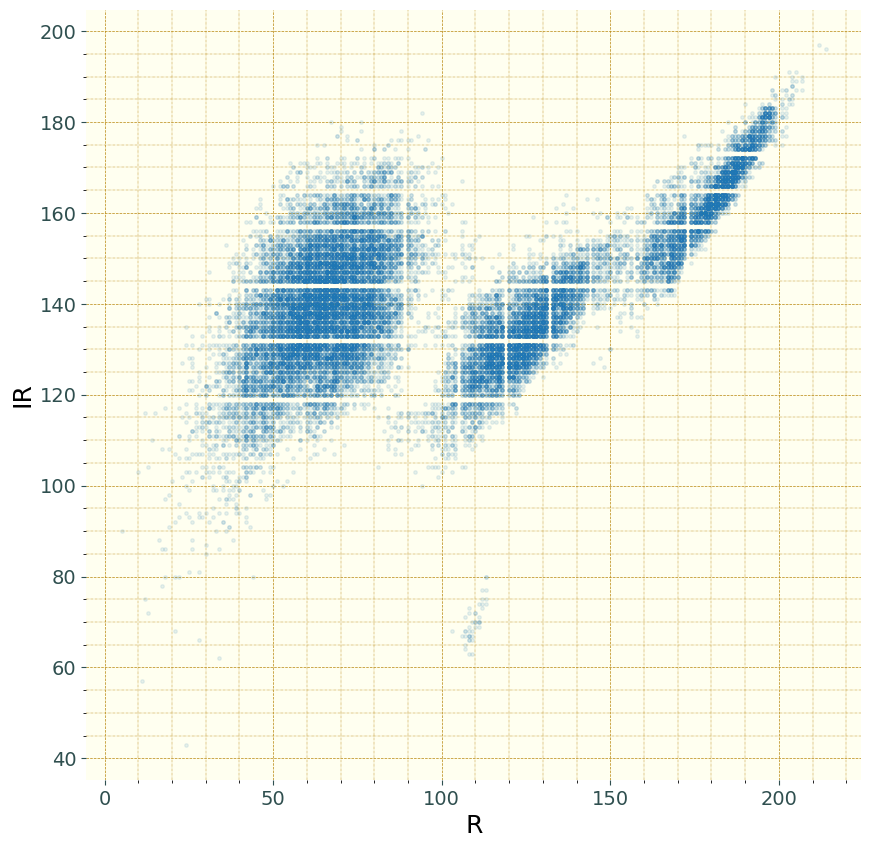

In [ ]:
# get desired bands
r = X[:, 1]
ir = X[:, 0]

# plot it
fig, ax = plt.subplots(figsize=(10, 10))
ax.plot(r, ir, '.', alpha=0.1, ms=5)

# custom the graph
plots.custom_bg(ax)
ax.set_ylabel('IR')
ax.set_xlabel('R')

findfont: Font family 'Sawasdee' not found.
findfont: Font family 'Sawasdee' not found.
findfont: Font family 'Sawasdee' not found.
findfont: Font family 'Sawasdee' not found.
findfont: Font family 'Sawasdee' not found.
findfont: Font family 'Sawasdee' not found.
findfont: Font family 'Sawasdee' not found.
findfont: Font family 'Sawasdee' not found.
findfont: Font family 'Sawasdee' not found.
findfont: Font family 'Sawasdee' not found.


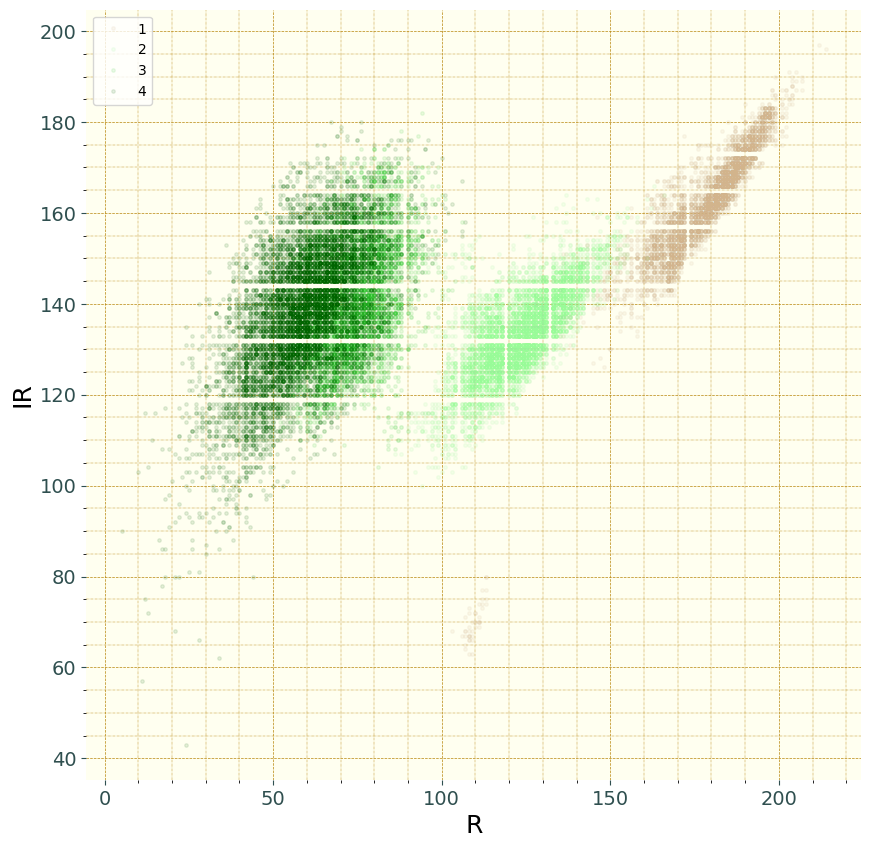

In [ ]:
# define colors
color = ['tan', 'palegreen', 'limegreen', 'darkgreen']

# define a new figure
fig, ax = plt.subplots(figsize=(10, 10))

# plot each class
for (class_number, X), col in zip(dict_X.items(), color):

    r = X[:, 1]
    ir = X[:, 0]
    ax.plot(r, ir, '.',
            alpha=0.1, # set transparency
            ms=5, # set point size
            color=col,
            label=class_number)

#custom grah
plots.custom_bg(ax)
ax.set_ylabel('IR')
ax.set_xlabel('R')
ax.legend()


In [22]:
import plotly.express as px


# convert data into dataframe
data = np.concatenate((X, Y), axis=1)
df = pd.DataFrame(data, columns=['IR', 'R', 'G', 'id'])
df['id'] = df['id'].astype(str)

# define color dictionnary
color = {'1':'tan', '2':'palegreen', '3':'limegreen', '4':'darkgreen'}

# plot data
fig = px.scatter(df,
                 x="R", y="IR",  # desired bands
                 color="id",  ## column containing the class label
                 hover_data=['id'],
                 color_discrete_map=color,  #color dictionnary
                 opacity=0.5,  # point opacity
                 height = 1000, width =1000)  # output figure size

# output parameters
out_folder = '/home/onyxia/work/data/td_classif'
out_figure = os.path.join(out_folder, '2D_scatter_plot.html')

#export graph
fig.write_html(out_figure)

In [23]:
color = {'1':'tan', '2':'palegreen', '3':'limegreen', '4':'darkgreen'}
data = np.concatenate((X, Y), axis=1)
df = pd.DataFrame(data, columns=['IR', 'R', 'G', 'id'])
df['id'] = df['id'].astype('int').astype(str)

In [25]:
import plotly.express as px
fig = px.scatter_3d(df, x="R", y="IR", z="G",
                    color="id",
                    hover_data=['id'],
                    color_discrete_map=color,
                    opacity=0.5,
                    height = 1000, width =1000)
out_folder = '/home/onyxia/work/data/td_classif'
out_figure = os.path.join(out_folder, '3D_scatter_plot.html')
fig.write_html(out_figure)


In [26]:
import plotly.express as px
fig = px.scatter_3d(df, x="R", y="IR", z="G",
                    color="id",
                    hover_data=['id'],
                    color_discrete_map=color,
                    opacity=0.5,
                    height = 1000, width =1000)
fig.update_traces(marker=dict(size=2,
                              line=dict(width=0.2,
                                        color='DarkSlateGrey')
                             )
                 )
out_folder = '/home/onyxia/work/data/td_classif'
out_figure = os.path.join(out_folder, '3D_scatter_plot_V2.html')
fig.write_html(out_figure)


In [27]:
import pandas as pd

color = {'1':'tan', '2':'palegreen', '3':'limegreen', '4':'darkgreen'}
r = X[:, 1].astype('int16')
ir = X[:, 0].astype('int16')
ndvi = (ir - r)/(ir + r)
ndvi = np.atleast_2d(ndvi).T
data = np.concatenate((X, Y, ndvi), axis=1)
df = pd.DataFrame(data, columns=['IR', 'R', 'G', 'id', "ndvi"])
df['id'] = df['id'].astype('int').astype(str)

In [29]:
import plotly.express as px
fig = px.scatter_3d(df, x="R", y="IR", z="ndvi",
                    color="id",
                    hover_data=['id'],
                    color_discrete_map=color,
                    opacity=0.5,
                    height = 1000, width =1000)
fig.update_traces(marker=dict(size=2,
                              line=dict(width=0.2,
                                        color='DarkSlateGrey')),
                  )
out_folder = '/home/onyxia/work/data/td_classif'
out_figure = os.path.join(out_folder, '3D_scatter_plot_V2_ndvi.html')
fig.write_html(out_figure)

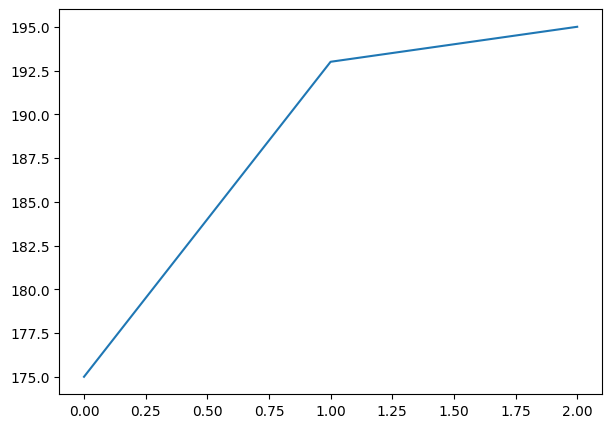

In [30]:
X = dict_X[1]
first_sample_signature = X[0, :]
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 5))
_ = ax.plot(first_sample_signature)

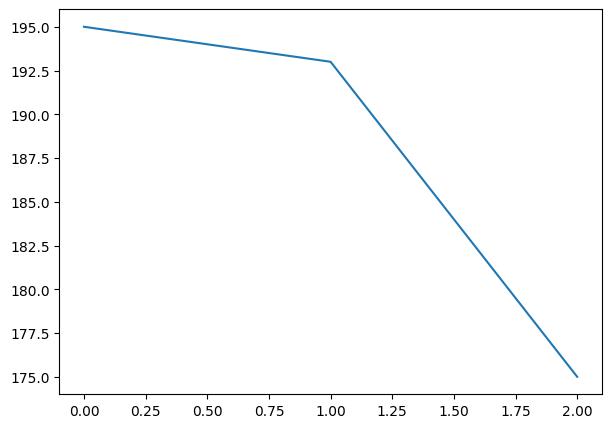

In [31]:
X = dict_X[1]
new_order = [2,1,0]
X = X[:, new_order]
first_sample_signature = X[0, :]
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 5))
_ = ax.plot(first_sample_signature)

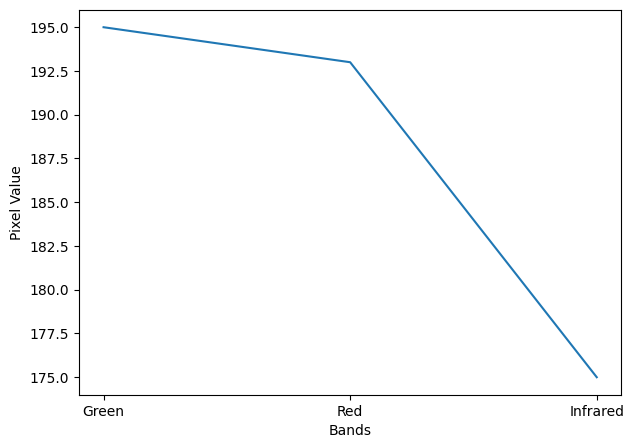

In [32]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 5))
_ = ax.plot(first_sample_signature)
ax.set_xticks(range(3))
ticks_labels = []
bands_name = ['Green', 'Red', 'Infrared']
_ = ax.set_xticklabels(bands_name)
_ = ax.set_ylabel('Pixel Value')
_ = ax.set_xlabel('Bands')

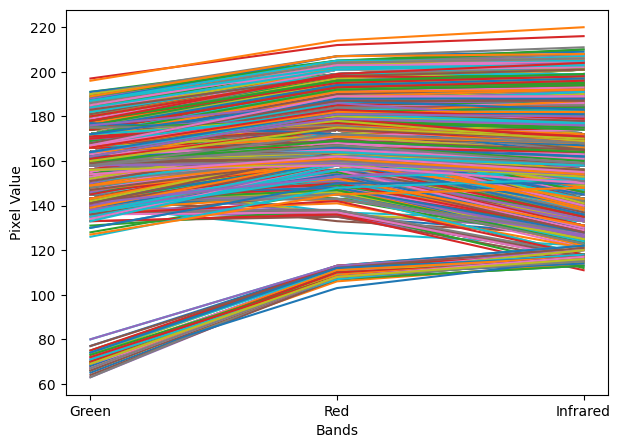

In [33]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 5))
X = dict_X[1]
_ = ax.plot(X.T)

ax.set_xticks(range(3))
ticks_labels = []
bands_name = ['Green', 'Red', 'Infrared']
_ = ax.set_xticklabels(bands_name)
_ = ax.set_ylabel('Pixel Value')
_ = ax.set_xlabel('Bands')

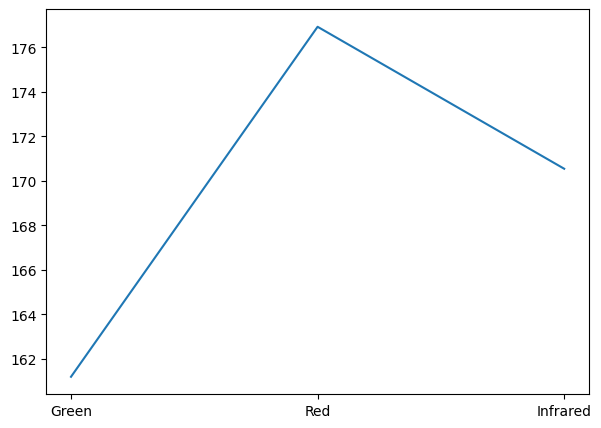

In [34]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 5))
means = X.mean(axis=0)
ax.plot(means)
ax.set_xticks(range(3))
ticks_labels = []
bands_name = ['Green', 'Red', 'Infrared']
_ = ax.set_xticklabels(bands_name)

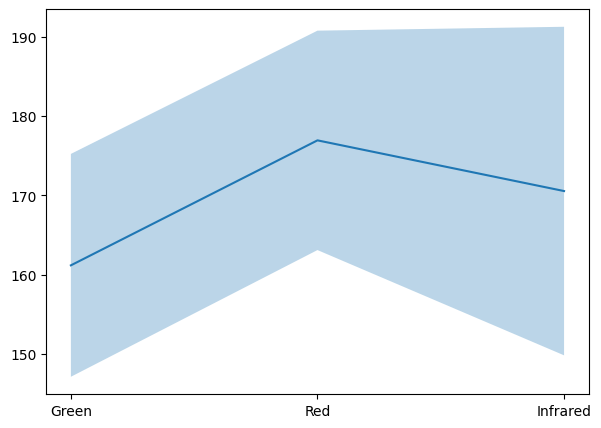

In [35]:
ig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 5))
means = X.mean(axis=0)
stds = X.std(axis=0)
ax.plot(means)
ax.fill_between(range(3), means + stds, means - stds, alpha=0.3)
ax.set_xticks(range(3))
ticks_labels = []
bands_name = ['Green', 'Red', 'Infrared']
_ = ax.set_xticklabels(bands_name)

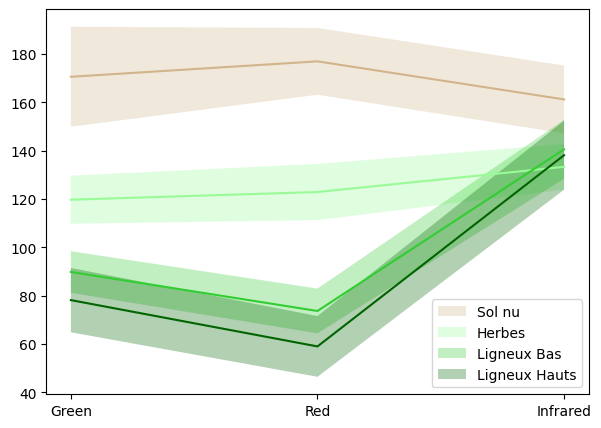

In [38]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 5))
colors = ['tan', 'palegreen', 'limegreen', 'darkgreen']
labels = ['Sol nu', 'Herbes', 'Ligneux Bas', 'Ligneux Hauts']
for X, color, label in zip(dict_X.values(), colors, labels):
    X = X[:, [2, 1, 0]]
    means = X.mean(axis=0)
    stds = X.std(axis=0)
    ax.plot(means, color=color)
    ax.fill_between(range(3), means + stds, means - stds, facecolor=color, alpha=0.3, label=label)
ax.set_xticks(range(3))
ticks_labels = []
bands_name = ['Green', 'Red', 'Infrared']
_ = ax.set_xticklabels(bands_name)
_ = ax.legend()


In [42]:
import matplotlib.pyplot as plt
from libsigma import read_and_write as rw

In [43]:
fabas_filename = '/home/onyxia/work/data/td_read_and_write/imagette_fabas.tif'
img = rw.load_img_as_array(fabas_filename)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [75..1680].


(np.float64(-0.5), np.float64(444.5), np.float64(500.5), np.float64(-0.5))

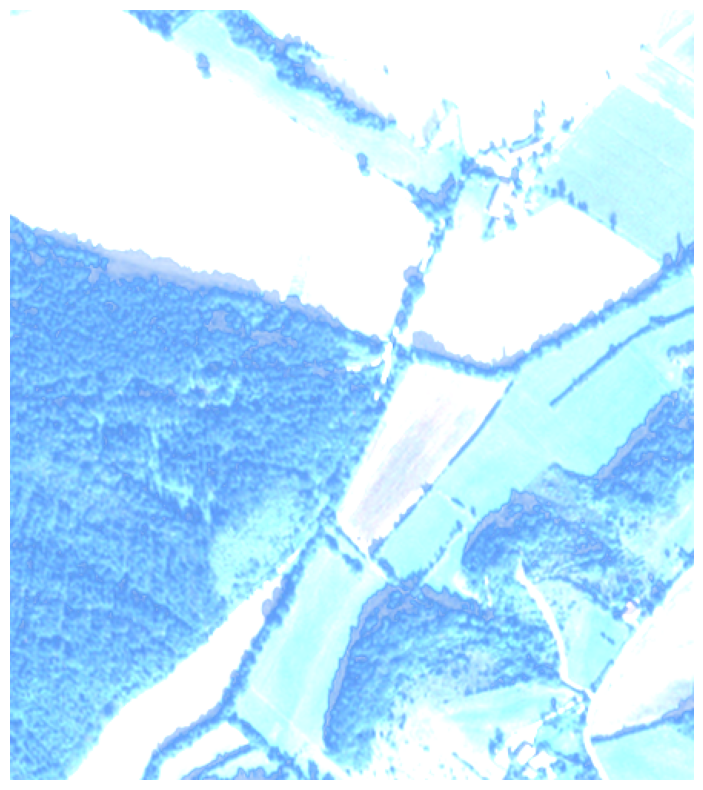

In [44]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(img)
ax.axis("off")  

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [75..1680].


(np.float64(-0.5), np.float64(444.5), np.float64(500.5), np.float64(-0.5))

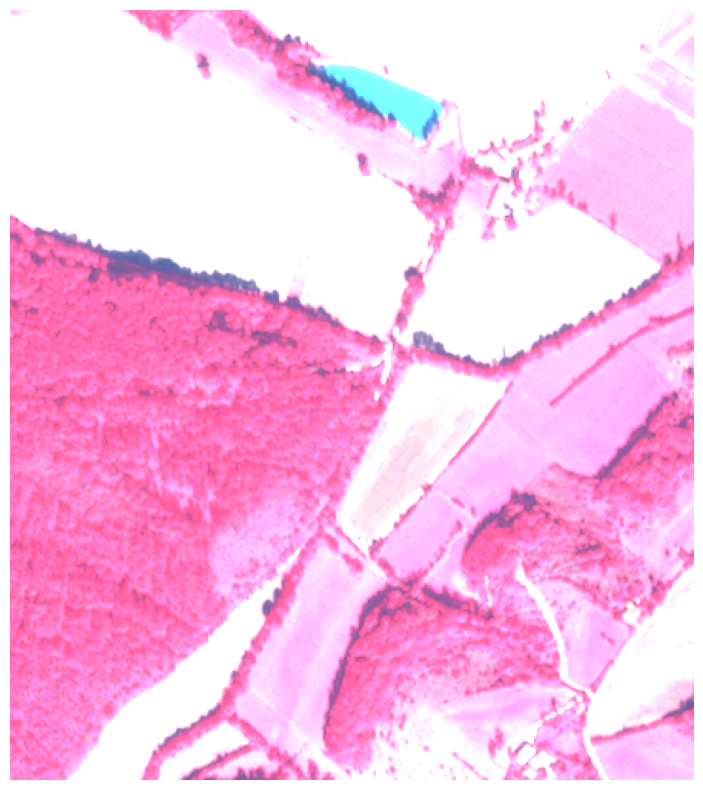

In [45]:
irc = img[:, :, :3].copy()
irc[:, :,0] = img[:, :,3]
irc[:, :,1] = img[:, :,0]
irc[:, :,2] = img[:, :,1]
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(irc)
ax.axis("off")

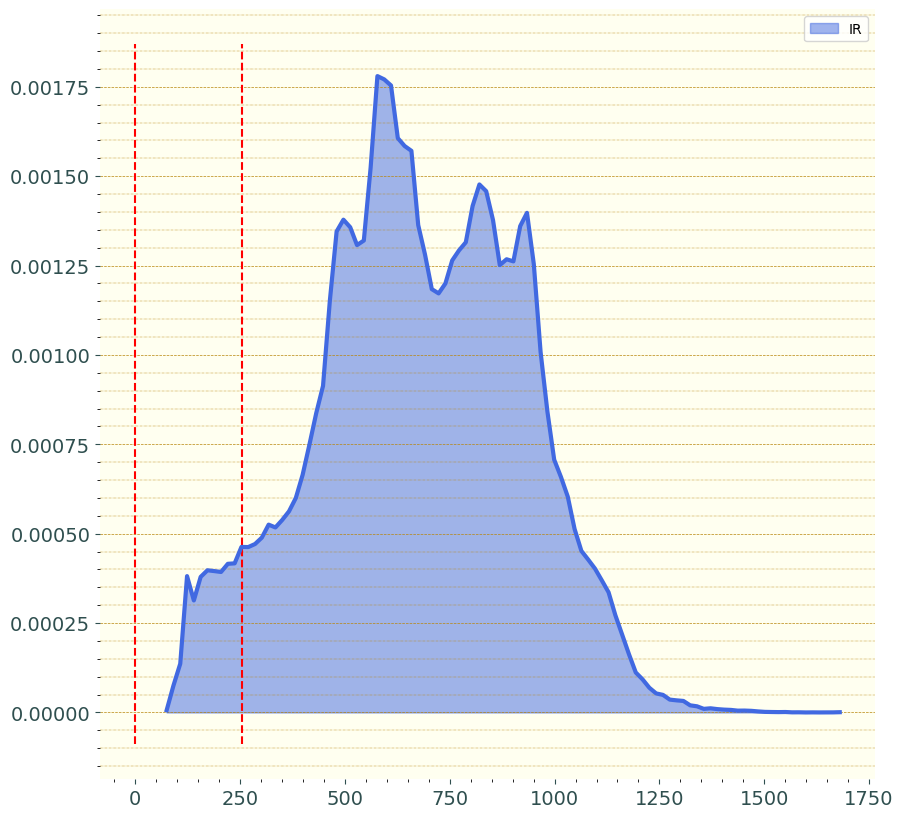

In [47]:
import matplotlib.pyplot as plt
from libsigma import plots
from sklearn.neighbors import KernelDensity

fig, ax = plt.subplots(figsize=(10, 10))

band = img[:,:,3].flatten()
# get 100 values between the min and the max of band
X_plot = np.linspace(band.min(), band.max(), 100)[:, np.newaxis]

# define kernel density
kde = KernelDensity(bandwidth=5)
# learn kernel
kde.fit(band.reshape(-1, 1))
# predict on our X
log_dens = kde.score_samples(X_plot)
density = np.exp(log_dens)

# plot it
ax.plot(X_plot[:,0], density , color='royalblue',
        zorder=3, linewidth=3,
        linestyle='-')
ax.fill_between(X_plot[:,0], 0, density, alpha=0.5, color='royalblue', label='IR')
ax.legend()
ax = plots.custom_bg(ax, x_grid=False)
min, max = ax.get_ylim()
_ = ax.vlines([0, 255], min, max, color='red', ls='--')

In [48]:
min_src = img.min(axis=(0, 1))
max_src = img.max(axis=(0, 1))
min_dst = 0
max_dst = 255
img_rescale = min_dst + (max_dst-min_dst) / (max_src-min_src) * (img-min_src)

In [49]:
print(img_rescale.max(axis=(0,1)))


[255. 255. 255. 255.]


(np.float64(-0.5), np.float64(444.5), np.float64(500.5), np.float64(-0.5))

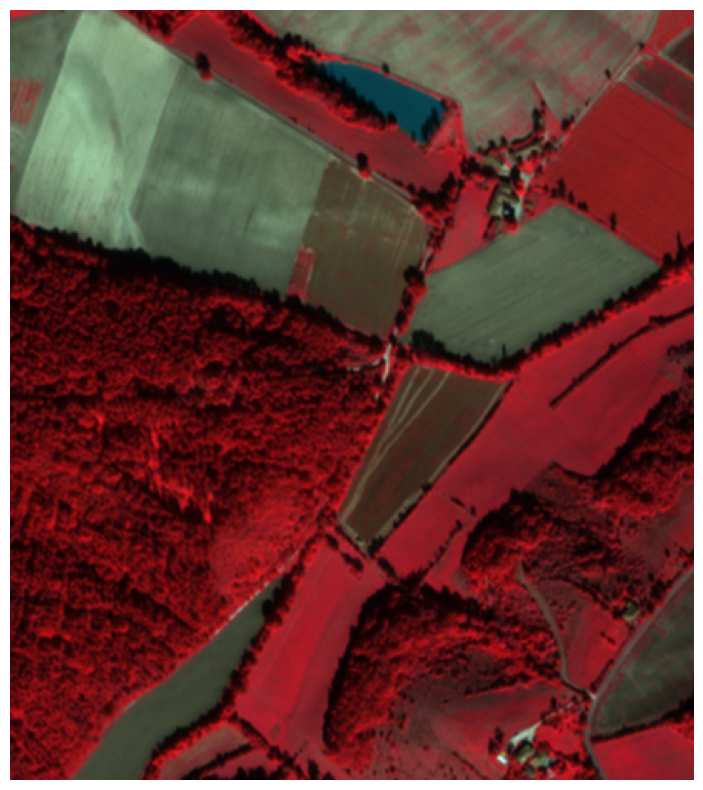

In [50]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 10))
irc = img_rescale[:, :, :3].copy().astype('uint8')
irc[:, :,0] = img_rescale[:, :,3]
irc[:, :,1] = img_rescale[:, :,0]
irc[:, :,2] = img_rescale[:, :,1]
ax.imshow(irc)
ax.axis("off")